In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(PROJECT_ROOT))

from analysis import (
    SingleExperimentLoader,
    ExperimentAggregator,
    StatisticalAnalyzer,
    TrajectoryVisualizer,
    HeatmapVisualizer,
    CollisionVisualizer,
    MetricsVisualizer,
    ScalingVisualizer,

)


In [2]:
exp_dir = PROJECT_ROOT / "experiments" / "experiment_average_sampling"
experiment = SingleExperimentLoader(exp_dir).load()
experiments = [experiment]


In [3]:
import re

agg = ExperimentAggregator(experiments)
df = agg.dataframe



df["strategy_full_name"] = df["strategy_name"].str.replace(
    r"_instance_\d+$",
    "",
    regex=True
)
df


,run_id,seed,strategy_name,planner,mission_makespan_steps,total_energy_consumed,total_distance_traveled,tasks_completed,unsafe_failures,messages_sent,...,distance_per_task,efficiency_ratio,failure_rate,n_drones,n_parcels,comm_reliability,battery_capacity,n_collisions,parcels_delivered,strategy_full_name
0,4b05372f,1769116958,naive_decentralized_reactive_instance_1,local,1541,111.857,40.0,12,490,0,...,3.333333,0.357599,40.833333,4,12,1.0,100.0,490,12,naive_decentralized_reactive
1,4b05372f,1769116958,cbba_auction_lb-cbba_instance_1,local,1094,119.682,43.0,12,301,45,...,3.583333,0.359285,25.083333,4,12,1.0,100.0,301,12,cbba_auction_lb-cbba
2,4b05372f,1769116958,centralized_cc_greedy_greedy_instance_1,local,1052,80.230,36.0,12,30,152,...,3.000000,0.448710,2.500000,4,12,1.0,100.0,30,12,centralized_cc_greedy_greedy
3,4b05372f,1769116958,centralized_cc_hungarian_hungarian_instance_1,local,962,80.761,36.0,12,67,83,...,3.000000,0.445760,5.583333,4,12,1.0,100.0,67,12,centralized_cc_hungarian_hungarian
4,4b05372f,1769116958,centralized_cc_auction_instance_1,local,963,79.911,35.0,12,15,106,...,2.916667,0.437987,1.250000,4,12,1.0,100.0,15,12,centralized_cc_auction
5,4b05372f,1769116958,sppdec_control_instance_1,local,1077,105.731,41.0,12,243,0,...,3.416667,0.387777,20.250000,4,12,1.0,100.0,243,12,sppdec_control
6,4b05372f,1769116958,sppdec_baseline_only_instance_1,local,931,99.055,40.0,12,178,0,...,3.333333,0.403816,14.833333,4,12,1.0,100.0,178,12,sppdec_baseline_only
7,4b05372f,1769116958,sppdec_fairness_only_instance_1,local,842,95.824,39.0,12,164,0,...,3.250000,0.406996,13.666667,4,12,1.0,100.0,164,12,sppdec_fairness_only
8,4b05372f,1769116958,sppdec_combined_instance_1,local,926,108.334,44.0,12,478,0,...,3.666667,0.406151,39.833333,4,12,1.0,100.0,478,12,sppdec_combined
9,4b05372f,1769116958,naive_decentralized_reactive_instance_2,local,1239,91.541,40.0,12,450,0,...,3.333333,0.436963,37.500000,4,12,1.0,100.0,450,12,naive_decentralized_reactive


In [4]:
metrics = [
    "mission_makespan_steps",
    "total_energy_consumed",
    "tasks_completed",
    "unsafe_failures",
    "runtime_seconds",
]

summary = (
    df
    .groupby("strategy_full_name")[metrics]
    .agg(["mean", "std", "min", "max", "count"])
    .round(3)
)

summary

mission_makespan_steps                 \
                                                     mean      std   min   
strategy_full_name                                                         
cbba_auction_lb-cbba                               1072.4   22.401  1041   
centralized_cc_auction                              991.6   24.825   963   
centralized_cc_greedy_greedy                       1048.6    3.209  1044   
centralized_cc_hungarian_hungarian                 1004.0   29.043   962   
naive_decentralized_reactive                       1408.2  130.145  1239   
sppdec_baseline_only                                963.0   21.131   931   
sppdec_combined                                     904.8  116.796   707   
sppdec_control                                      940.0  142.496   715   
sppdec_fairness_only                                861.0  134.607   698   

                                               total_energy_consumed         \
                                     max count                  mean    std   
strategy_full_name                                                            
cbba_auction_lb-cbba                1094     5               113.165  4.298   
centralized_cc_auction              1019     5                81.666  2.223   
centralized_cc_greedy_greedy        1052     5                82.460  1.628   
centralized_cc_hungarian_hungarian  1031     5                81.747  2.196   
naive_decentralized_reactive        1541     5               104.421  7.662   
sppdec_baseline_only                 987     5               102.836  4.345   
sppdec_combined                     1019     5                99.942  8.353   
sppdec_control                      1077     5               100.418  8.978   
sppdec_fairness_only                 998     5                96.398  7.661   

                                                            ...  \
                                        min      max count  ...   
strategy_full_name                                          ...   
cbba_auction_lb-cbba                107.795  119.682     5  ...   
centralized_cc_auction               79.722   84.831     5  ...   
centralized_cc_greedy_greedy         80.230   84.678     5  ...   
centralized_cc_hungarian_hungarian   78.572   84.320     5  ...   
naive_decentralized_reactive         91.541  111.857     5  ...   
sppdec_baseline_only                 97.492  107.685     5  ...   
sppdec_combined                      90.499  108.334     5  ...   
sppdec_control                       88.091  108.484     5  ...   
sppdec_fairness_only                 88.712  106.220     5  ...   

                                   unsafe_failures                           \
                                              mean      std  min  max count   
strategy_full_name                                                            
cbba_auction_lb-cbba                         255.8   60.097  182  305     5   
centralized_cc_auction                        27.0   12.550   15   45     5   
centralized_cc_greedy_greedy                  30.0    0.000   30   30     5   
centralized_cc_hungarian_hungarian            51.4   26.745   15   86     5   
naive_decentralized_reactive                 576.2  109.887  450  708     5   
sppdec_baseline_only                         316.2   99.150  178  445     5   
sppdec_combined                              267.2  168.204   62  478     5   
sppdec_control                               288.0  163.928   65  506     5   
sppdec_fairness_only                         249.4  100.448  130  355     5   

                                   runtime_seconds                         \
                                              mean    std     min     max   
strategy_full_name                                                          
cbba_auction_lb-cbba                        22.636  0.364  22.138  22.993   
centralized_cc_auction                      21.376  0.402  20.913  21.826   
centralized_cc_greedy_greedy      

In [5]:
best_runs = (
    df.loc[df.groupby("strategy_full_name")["mission_makespan_steps"].idxmin()]
    .sort_values("mission_makespan_steps")
)

best_runs[["strategy_full_name", "mission_makespan_steps"]]

,strategy_full_name,mission_makespan_steps
25,sppdec_fairness_only,698
17,sppdec_combined,707
23,sppdec_control,715
6,sppdec_baseline_only,931
3,centralized_cc_hungarian_hungarian,962
4,centralized_cc_auction,963
19,cbba_auction_lb-cbba,1041
20,centralized_cc_greedy_greedy,1044
9,naive_decentralized_reactive,1239


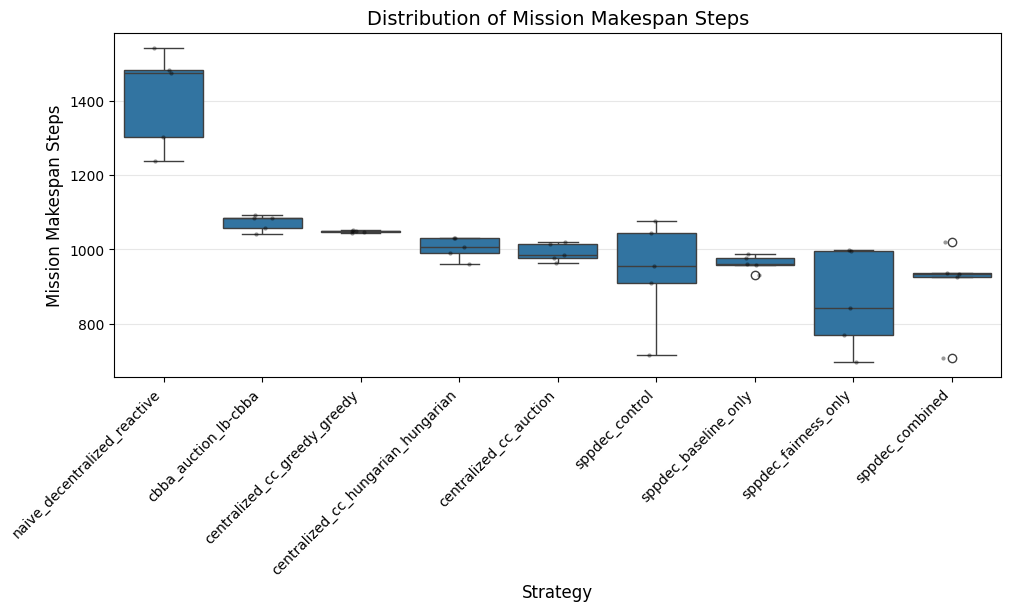

In [6]:
viz = MetricsVisualizer()
viz.plot_metric_distribution(df, "mission_makespan_steps")

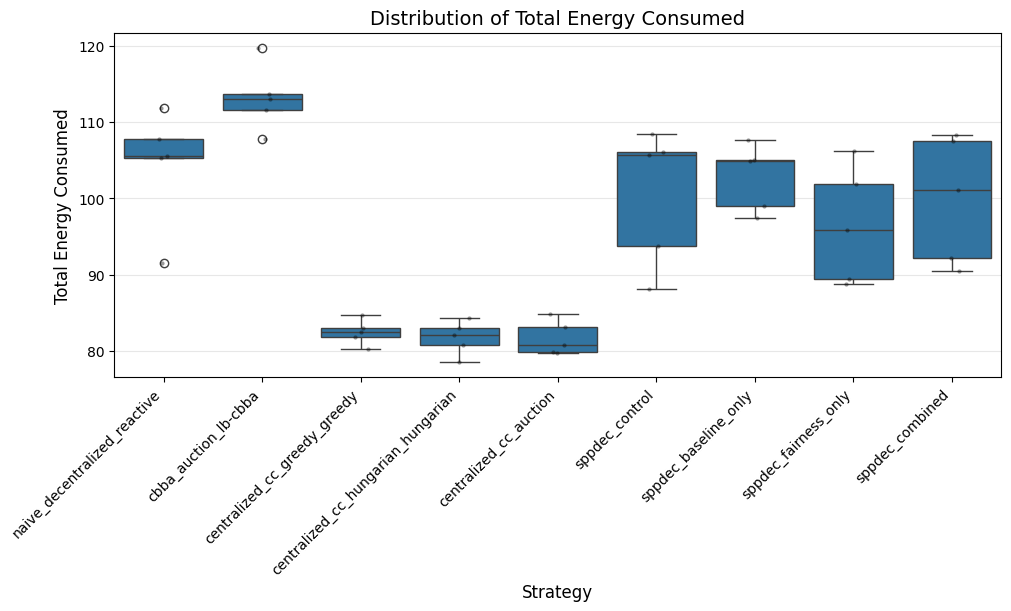

In [7]:
viz.plot_metric_distribution(df, "total_energy_consumed")

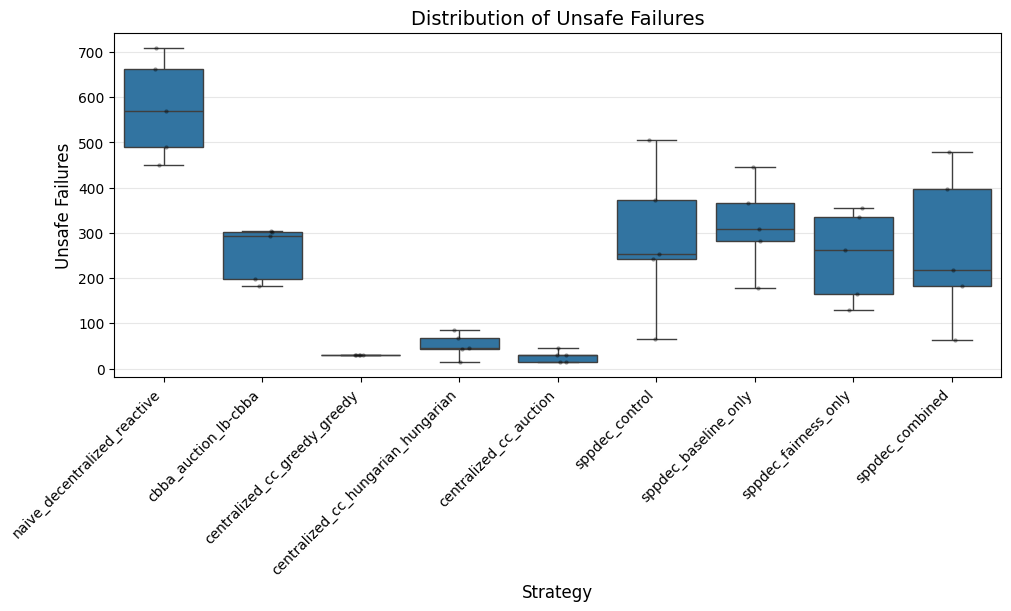

In [8]:
viz.plot_metric_distribution(df, "unsafe_failures")

In [ ]:
viz.plot_pareto_runs(
    df,
    x_metric="mission_makespan_steps",
    y_metric="total_energy_consumed"
)

In [ ]:
viz.plot_mean_ci(df, "mission_makespan_steps")

In [ ]:
viz.plot_mean_ci(df, "unsafe_failures")

In [ ]:
viz.plot_rank_distribution(df, "mission_makespan_steps")

In [ ]:
s_viz = ScalingVisualizer()

# Agents scaling
s_viz.plot_scaling(
    df,
    metric="mission_makespan_steps",
    x_axis="n_drones"
)

# Parcels scaling
s_viz.plot_scaling(
    df,
    metric="total_energy_consumed",
    x_axis="n_parcels"
)

# 2D performance landscape for one strategy
s_viz.plot_surface(
    df,
    metric="mission_makespan_steps",
    group="sppdec_combined"
)


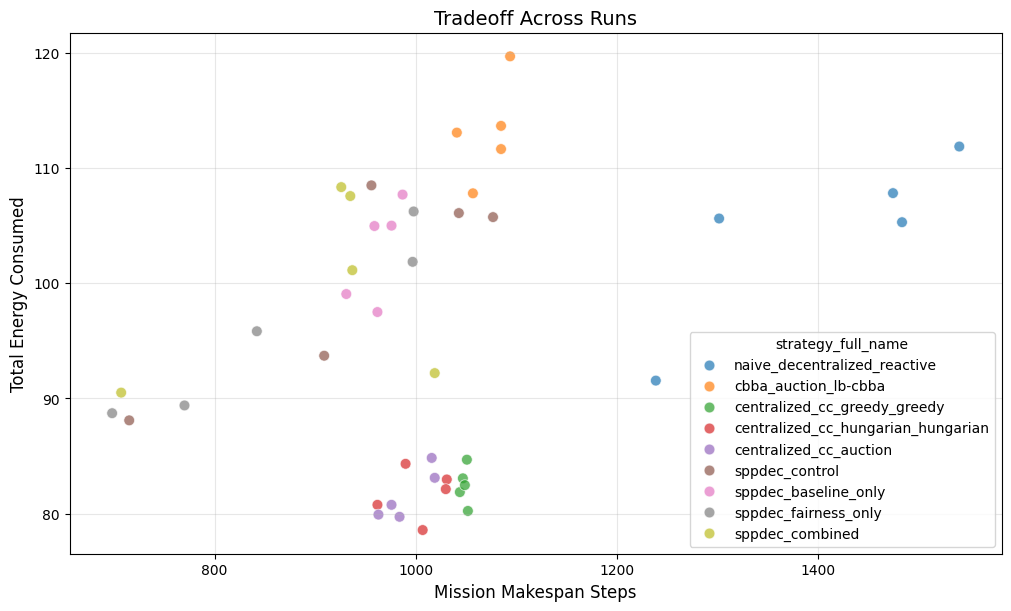

In [9]:
s_viz = ScalingVisualizer()

# Agents scaling
s_viz.plot_scaling(
    df,
    metric="mission_makespan_steps",
    x_axis="n_drones"
)

# Parcels scaling
s_viz.plot_scaling(
    df,
    metric="total_energy_consumed",
    x_axis="n_parcels"
)

# 2D performance landscape for one strategy
s_viz.plot_surface(
    df,
    metric="mission_makespan_steps",
    group="sppdec_combined"
)


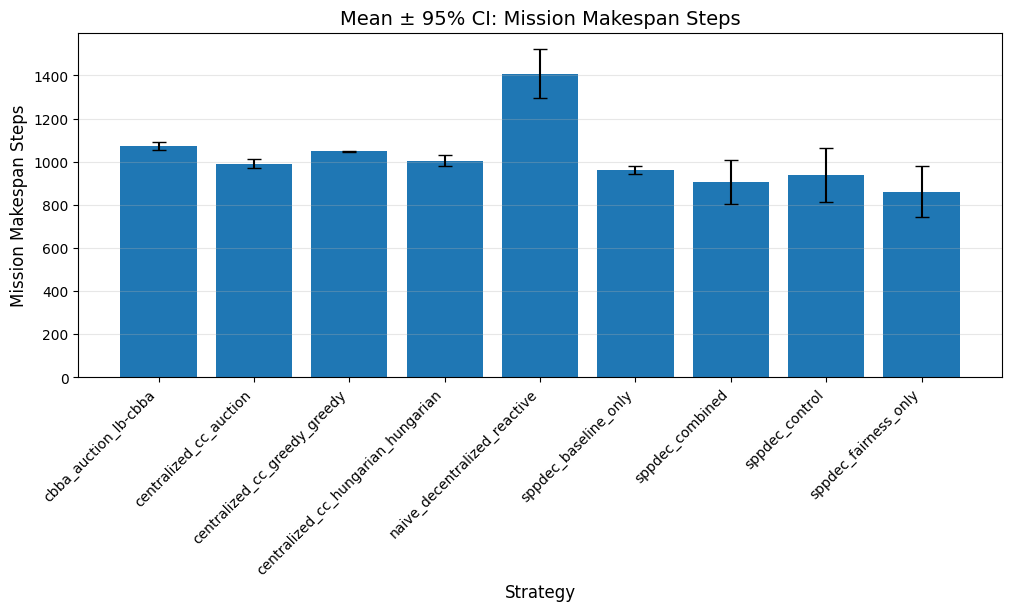

In [10]:
viz.plot_mean_ci(df, "mission_makespan_steps")

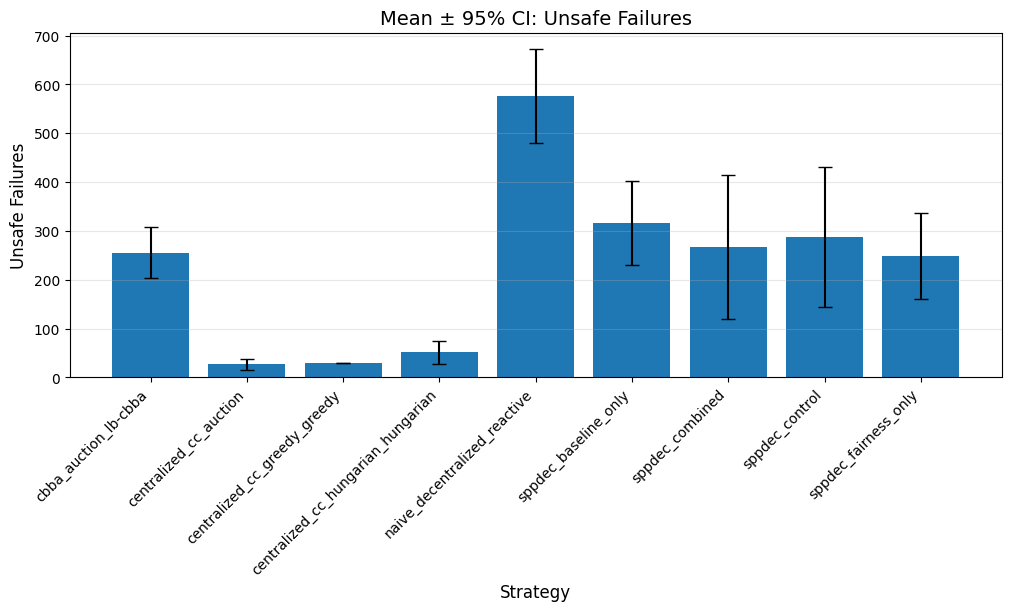

In [11]:
viz.plot_mean_ci(df, "unsafe_failures")

/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/visualizers.py:697: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df


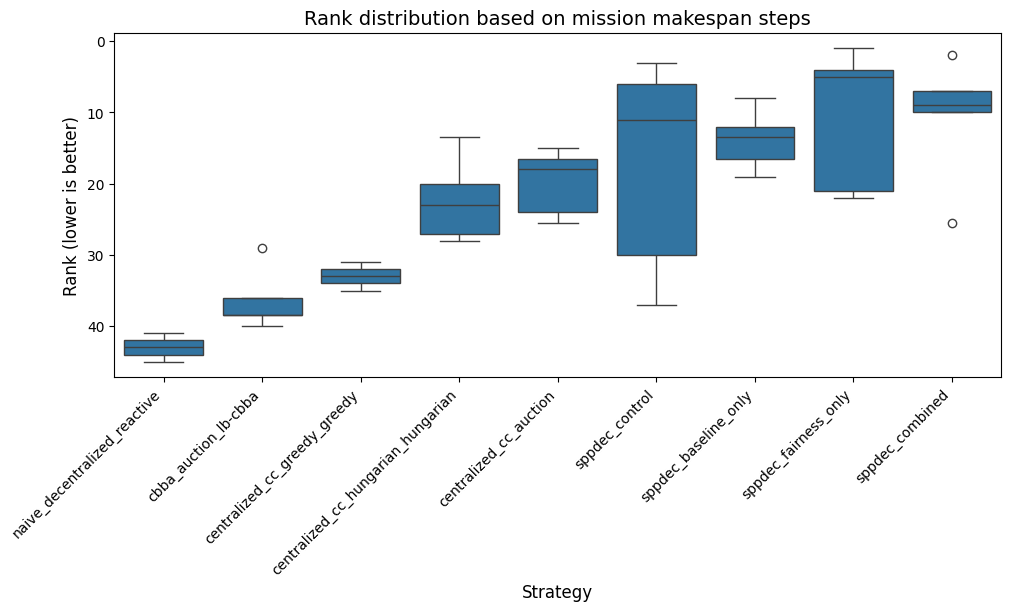

In [12]:
viz.plot_rank_distribution(df, "mission_makespan_steps")

In [ ]:
s_viz = ScalingVisualizer()

# Agents scaling
s_viz.plot_scaling(
    df,
    metric="mission_makespan_steps",
    x_axis="n_drones"
)

# Parcels scaling
s_viz.plot_scaling(
    df,
    metric="total_energy_consumed",
    x_axis="n_parcels"
)

# 2D performance landscape for one strategy
s_viz.plot_surface(
    df,
    metric="mission_makespan_steps",
    group="sppdec_combined"
)
